# Module 04 · Stage coupling and feedback

In [1]:
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Gain product and decibels

In [2]:
A = 15**4; print(f"15^4 = {A:,}  -> {20*np.log10(A):.1f} dB  (= 4 x {20*np.log10(15):.2f} dB)")
print("3 stages of 10 dB: gain =", round(10**(30/20), 1))
for av in (12, 50, 100, 2500): print(av, "->", round(20*np.log10(av), 2), "dB")

15^4 = 50,625  -> 94.1 dB  (= 4 x 23.52 dB)
3 stages of 10 dB: gain = 31.6
12 -> 21.58 dB
50 -> 33.98 dB
100 -> 40.0 dB
2500 -> 67.96 dB


**Comment:** 15⁴ = 50,625 corresponds to 94.1 dB = 4 × 23.52 dB; three 10 dB stages give 31.6 — dB add while ratios multiply.

## 2. Negative feedback desensitises the gain to the open-loop gain

In [3]:
B = 0.02
for A in (50000, 100000, 200000):
    print(f"A = {A:>7,}: Acl = {A/(1+A*B):.4f}")
A1, A2 = 100000, 120000
c1, c2 = A1/(1+A1*B), A2/(1+A2*B)
print(f"A changes +{(A2/A1-1)*100:.0f} % -> Acl changes +{(c2/c1-1)*100:.4f} %")

A =  50,000: Acl = 49.9500
A = 100,000: Acl = 49.9750
A = 200,000: Acl = 49.9875
A changes +20 % -> Acl changes +0.0083 %


**Comment:** when A rises 20 %, Acl changes only about 0.0083 % around 49.98 — negative feedback makes the closed-loop gain depend almost only on B (≈ 1/B = 50).

## 3. RC coupling: low-frequency response

fc = 15.4 Hz;  C for fc=20 Hz: 1.69 uF
f =    1.54 Hz: |H| = 0.100 (-20.04 dB)
f =   15.39 Hz: |H| = 0.707 (-3.01 dB)
f =  153.92 Hz: |H| = 0.995 (-0.04 dB)


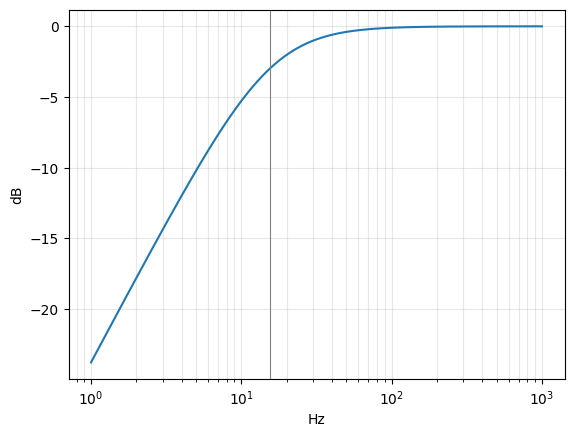

In [4]:
R, C = 4.7e3, 2.2e-6
fc = 1/(2*np.pi*R*C); print(f"fc = {fc:.1f} Hz;  C for fc=20 Hz: {1/(2*np.pi*20*R)*1e6:.2f} uF")
f = np.logspace(0, 3, 300); H = 1/np.sqrt(1+(fc/f)**2)
for ff in (fc/10, fc, 10*fc): print(f"f = {ff:7.2f} Hz: |H| = {1/np.sqrt(1+(fc/ff)**2):.3f} ({20*np.log10(1/np.sqrt(1+(fc/ff)**2)):.2f} dB)")
plt.semilogx(f, 20*np.log10(H)); plt.axvline(fc, color="gray", lw=.8); plt.xlabel("Hz"); plt.ylabel("dB"); plt.grid(alpha=.3, which="both"); plt.show()

**Comment:** with 4.7 kΩ and 2.2 μF, fc ≈ 15.4 Hz; at fc the gain is down 3 dB (0.707) and at fc/10 only 0.0995 remains — the coupling capacitor blocks signals well below fc.

## 4. Class A and class B efficiency versus amplitude

In [5]:
# class B push-pull: eta = (pi/4)*(Vp/VCC);  class A (series-fed, Q at VCC/2): eta = 0.25*(Vp/(VCC/2))**2
for x in (0.25, 0.5, 0.75, 1.0):
    etaB = np.pi/4*x; etaA = 0.25*x**2
    print(f"Vp/VCC = {x:4.2f}: class B eta = {etaB*100:5.1f} %, class A eta (Vp/(VCC/2)={x:.2f}) = {etaA*100:5.1f} %")
print("class B maximum:", round(np.pi/4*100, 1), "%; class A series-fed maximum: 25.0 %")

Vp/VCC = 0.25: class B eta =  19.6 %, class A eta (Vp/(VCC/2)=0.25) =   1.6 %
Vp/VCC = 0.50: class B eta =  39.3 %, class A eta (Vp/(VCC/2)=0.50) =   6.2 %
Vp/VCC = 0.75: class B eta =  58.9 %, class A eta (Vp/(VCC/2)=0.75) =  14.1 %
Vp/VCC = 1.00: class B eta =  78.5 %, class A eta (Vp/(VCC/2)=1.00) =  25.0 %
class B maximum: 78.5 %; class A series-fed maximum: 25.0 %


**Comment:** class B reaches a maximum of π/4 ≈ 78.5 % when the amplitude equals VCC; the series-fed class A reaches at most 25 % — consistent with Floyd (79 %, 25 %); EASA’s “about twice as efficient” is a rough statement, and the maximum figures give a larger ratio.